# Practical tasks

##### Please explore the datasets and answer the questions below.
##### Here are some guidlines and advices you should consider:
* you can add as many cells as is comfortable for you for each answer
* some questions require your explanation. Add a cell and choose a markdown option in the menu 
* when you are making plots, please add labels to the axes

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import scipy.cluster.hierarchy as shc
import seaborn as sns
from sklearn.cluster import (
    KMeans,
    AgglomerativeClustering,
    DBSCAN
    )
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV
    )
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    roc_auc_score,
    recall_score,
    precision_score,
    confusion_matrix
)
# you will need to import more libraries as needed

# Clustering tasks

The problem that we are going to solve in this section is to segment customers into different groups based on their shopping trends.

The dataset for this problem `shopping-data.csv`

#### 1. Load the data and preview

In [2]:
customer_data = pd.read_csv('shopping-data.csv', index_col=0)

In [3]:
customer_data.head()

,Gender,Age,Annual Income (k$),Spending Score (1-100)
CustomerID,,,,
1,Male,19,15,39
2,Male,21,15,81
3,Female,20,16,6
4,Female,23,16,77
5,Female,31,17,40


In [4]:
customer_data.describe()

,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000
mean,38.850000,60.560000,50.200000
std,13.969007,26.264721,25.823522
min,18.000000,15.000000,1.000000
25%,28.750000,41.500000,34.750000
50%,36.000000,61.500000,50.000000
75%,49.000000,78.000000,73.000000
max,70.000000,137.000000,99.000000


#### 2. Plot scatter plot for annual income and spending score which will be used for clustering in the next steps

In [5]:
df = customer_data.copy()
df = df.drop(['Gender', 'Age'], axis=1)
df.head()

,Annual Income (k$),Spending Score (1-100)
CustomerID,,
1,15,39
2,15,81
3,16,6
4,16,77
5,17,40


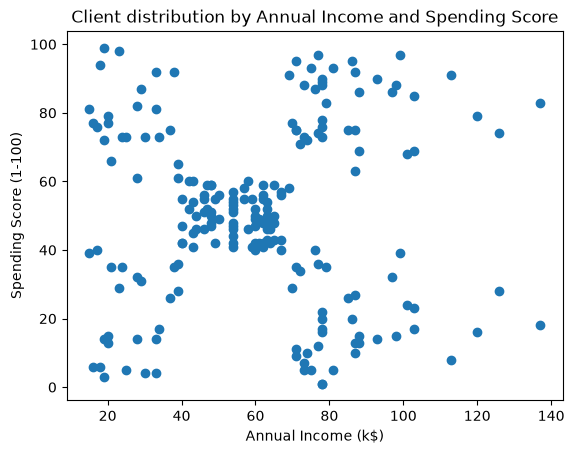

In [6]:
plt.scatter(x=df["Annual Income (k$)"], y=df["Spending Score (1-100)"])
plt.title("Client distribution by Annual Income and Spending Score")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.show()

#### 3. Normalize the data

In [7]:
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df)

#### 4. Use Elbow method to decide number of clusters

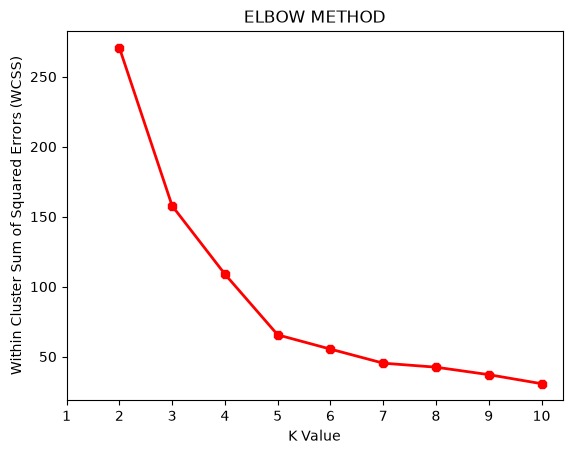

In [8]:
elbow=[]
for i in range(2, 11):
    kmeans = KMeans(n_clusters=i)
    kmeans.fit(df_scaled)
    elbow.append(kmeans.inertia_)

plt.plot(range(2, 11), elbow, linewidth=2, color="red", marker ="8")
plt.title('ELBOW METHOD')
plt.xlabel("K Value")
plt.xticks(np.arange(1,11,1))
plt.ylabel("Within Cluster Sum of Squared Errors (WCSS)")
plt.show()

#### 5. Perform Clustering using KMeans

In [9]:
km = KMeans(n_clusters=5)
km.fit(df_scaled)

y = km.predict(df_scaled)

df["Label"] = y
df.head()

,Annual Income (k$),Spending Score (1-100),Label
CustomerID,,,
1,15,39,4
2,15,81,3
3,16,6,4
4,16,77,3
5,17,40,4


#### 6. Plot scatter plot and color code in clustered groups

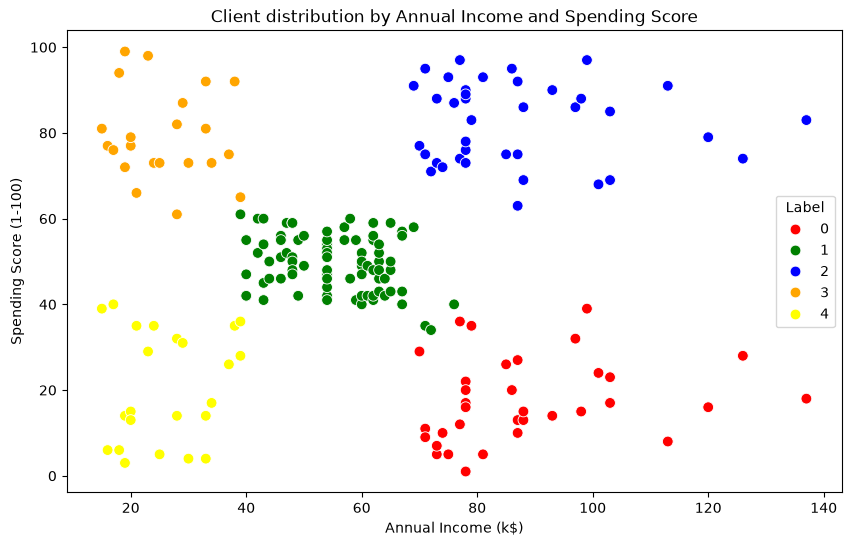

In [10]:
plt.figure(figsize=(10,6))
sns.scatterplot(x = 'Annual Income (k$)', y = 'Spending Score (1-100)', hue="Label",  
    palette=['red','green','blue','orange','yellow'], legend='full',data = df, s = 60 )
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)') 
plt.title('Client distribution by Annual Income and Spending Score')
plt.show()

#### 7. Plot dendrogram to decide number of clusters for Hierarchical Clustering. <br> Explain (free text in a markdown cell) what is the optimal number of clusters and why

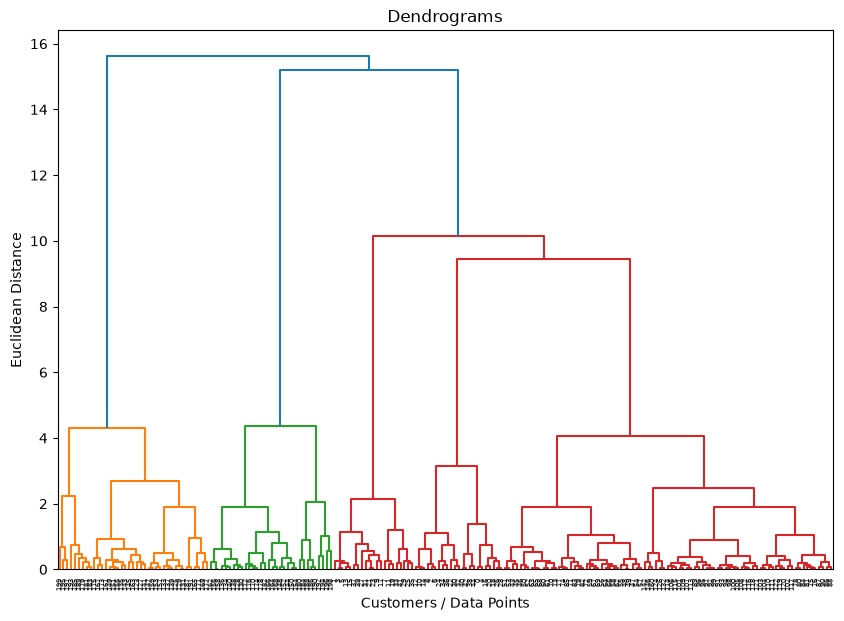

In [11]:
plt.figure(figsize=(10, 7))  
plt.title("Dendrograms")  
dend = shc.dendrogram(shc.linkage(df_scaled, method='ward'))
plt.xlabel("Customers / Data Points")
plt.ylabel("Euclidean Distance")
plt.show()

### Explanation of task 7
Optimal number of clusters is 5 because there are 5 vertical segments between positions $y \approx 4$ and $y \approx 9$ which are one of the longest segments in the dendrogram.

#### 8. Do clustering using Hierarchical Clustering

In [12]:
hc = AgglomerativeClustering(n_clusters=5, metric='euclidean', linkage='ward')
y_hc = hc.fit_predict(df_scaled)

#### 9. Plot scatter plot and color code in clustered groups

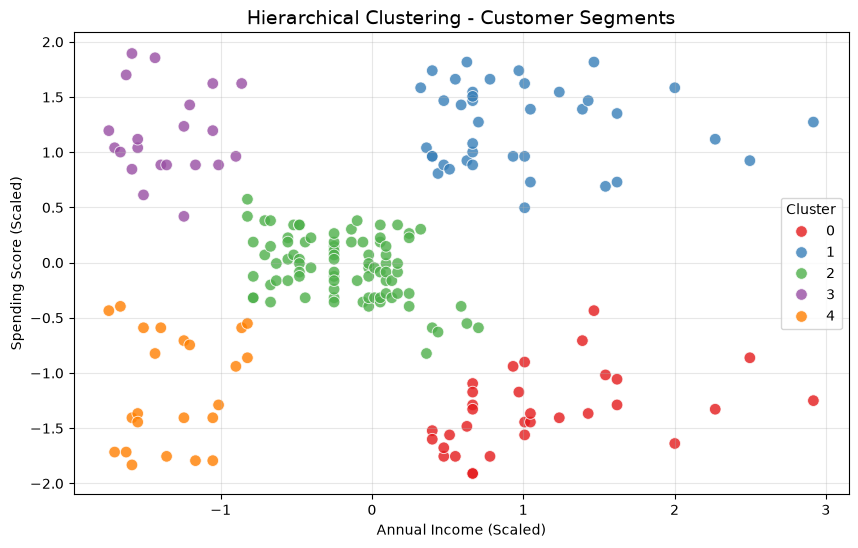

In [13]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=df_scaled[:, 0],
    y=df_scaled[:, 1],
    hue=y_hc,
    palette='Set1',
    s=70,
    alpha=0.8
)

plt.title('Hierarchical Clustering - Customer Segments', fontsize=14)
plt.xlabel('Annual Income (Scaled)')
plt.ylabel('Spending Score (Scaled)')
plt.legend(title='Cluster')
plt.grid(alpha=0.3)

####  10. Do KMeans and DBSCAN clustering on this data

In [14]:
from sklearn.datasets import make_moons
#moons_X: Data, moon_y: Labels
moons_X, moon_y = make_moons(n_samples=2000)

Text(0.5, 1.0, 'Half Moons')

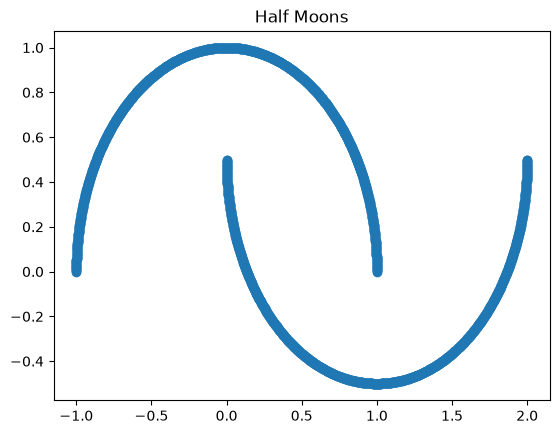

In [15]:
plt.scatter(moons_X[:,0],moons_X[:,1])
plt.title('Half Moons')

#### Using KMeans (do clustering and plot results (each cluster in own color))

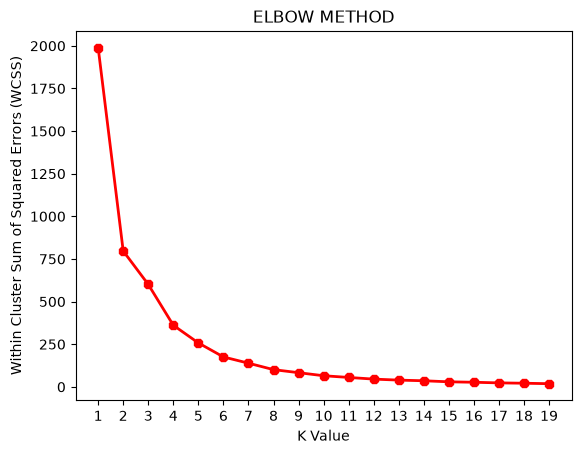

In [16]:
elbow=[]
for i in range(1, 20):
    kmeans = KMeans(n_clusters=i)
    kmeans.fit(moons_X)
    elbow.append(kmeans.inertia_)

plt.plot(range(1, 20), elbow, linewidth=2, color="red", marker ="8")
plt.title('ELBOW METHOD')
plt.xlabel("K Value")
plt.xticks(np.arange(1,20,1))
plt.ylabel("Within Cluster Sum of Squared Errors (WCSS)")
plt.show()

In [17]:
km2 = KMeans(n_clusters=2, init="k-means++")
y = km2.fit_predict(moons_X)

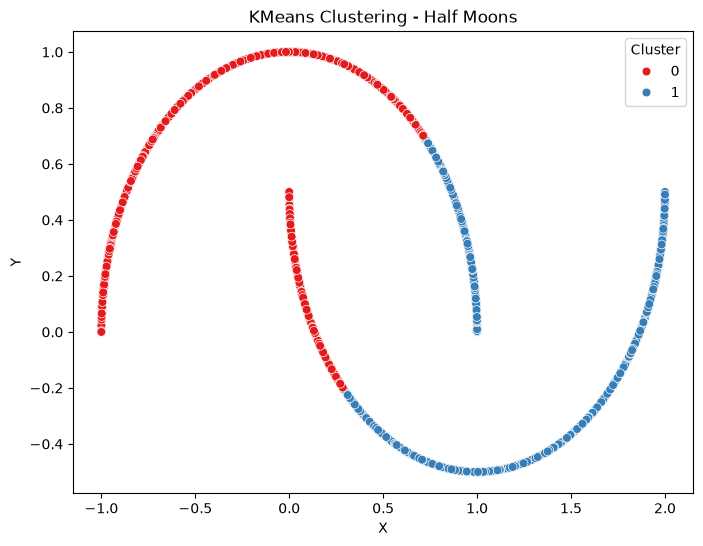

In [18]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=moons_X[:, 0],
    y=moons_X[:, 1],
    hue=y,
    palette='Set1',
    s=40
)

plt.title('KMeans Clustering - Half Moons')
plt.xlabel('X')
plt.ylabel('Y')
plt.legend(title='Cluster')
plt.show()

#### 11. Using DBSCAN do clustering and plot results (each cluster in own color). Find the most suitable eps and minimal samples number

In [19]:
model = DBSCAN(eps=0.1, min_samples=5)
yhat = model.fit_predict(moons_X)
clusters = np.unique(yhat)
clusters

array([0, 1])

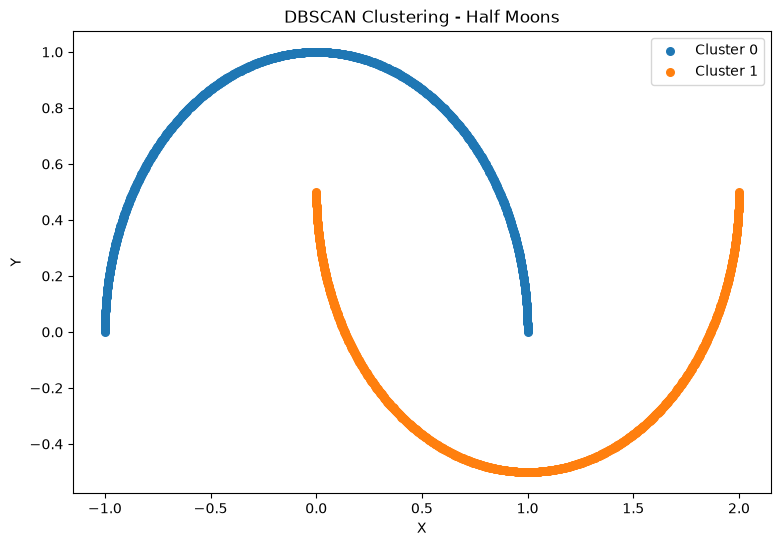

In [20]:
plt.figure(figsize=(9, 6))

for cluster in clusters:
    row_ix = np.where(yhat == cluster)[0]

    plt.scatter(
        moons_X[row_ix, 0],
        moons_X[row_ix, 1],
        label=f'Cluster {cluster}',
        s=30
    )

plt.title('DBSCAN Clustering - Half Moons')
plt.xlabel('X')
plt.ylabel('Y')
plt.legend()
plt.show()

#### 12. Compare the results of K-means and DBSCAN clustering
Explain why one or another is prefferable for such dataset, and differences if any.

For such kind of dataset, `DBSCAN` clustering is prefferable because `DBSCAN` groups moons by clusters, while `K-means` groups by *centroids* which might be random and then each point is associated with the nearest centroid which explains why it did not separate 2 moons like we would like it to.

### Perform PCA on penguins :)
###### This section uses kaggle dataset (https://www.kaggle.com/datasets/youssefaboelwafa/clustering-penguins-species/data)
###### The tasks below include data analysis, data preprocessing, PCA, and application of classification to predict the target

#### 13. Describe the data. Do any additional exporations as you feel

In [21]:
# Dataset
penguins = pd.read_csv('penguins.csv')
penguins.head()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,39.1,18.7,181.0,3750.0,MALE
1,39.5,17.4,186.0,3800.0,FEMALE
2,40.3,18.0,195.0,3250.0,FEMALE
3,NaN,NaN,NaN,NaN,NaN
4,36.7,19.3,193.0,3450.0,FEMALE


In [22]:
penguins.shape

(344, 5)

In [23]:
penguins.info()

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   culmen_length_mm   342 non-null    float64
 1   culmen_depth_mm    342 non-null    float64
 2   flipper_length_mm  342 non-null    float64
 3   body_mass_g        342 non-null    float64
 4   sex                335 non-null    str    
dtypes: float64(4), str(1)
memory usage: 13.6 KB


In [24]:
penguins.isna().sum()

culmen_length_mm     2
culmen_depth_mm      2
flipper_length_mm    2
body_mass_g          2
sex                  9
dtype: int64

#### Based on dataframe describe, in own words explain any abnormal characteristics 

Dataframe has 344 rows, 5 columns. 4 Numerical and 1 categorical columns. All columns have atleast 2 missing values while `sex` column has 9.

#### 14. Explore corrupted data

In [25]:
# find missing values. print entries with missing values
penguins[penguins.isna().any(axis=1)]

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
3,NaN,NaN,NaN,NaN,NaN
8,34.1,18.1,193.0,3475.0,NaN
10,37.8,17.1,186.0,3300.0,NaN
11,37.8,17.3,180.0,3700.0,NaN
47,37.5,18.9,179.0,2975.0,NaN
246,44.5,14.3,216.0,4100.0,NaN
286,46.2,14.4,214.0,4650.0,NaN
324,47.3,13.8,216.0,4725.0,NaN
339,NaN,NaN,NaN,NaN,NaN


In [26]:
# provide shape
penguins[penguins.isna().any(axis=1)].shape

(9, 5)

In [27]:
# Examine sex column
penguins['sex'].value_counts(dropna=False)
# Noticed the '.' value and 9 NaN.

sex
MALE      169
FEMALE    165
NaN         9
.           1
Name: count, dtype: int64

In [28]:
# find any unusual values.
penguins.describe()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
count,342.000000,342.000000,342.000000,342.000000
mean,43.921930,17.151170,214.014620,4201.754386
std,5.459584,1.974793,260.558057,801.954536
min,32.100000,13.100000,-132.000000,2700.000000
25%,39.225000,15.600000,190.000000,3550.000000
50%,44.450000,17.300000,197.000000,4050.000000
75%,48.500000,18.700000,213.750000,4750.000000
max,59.600000,21.500000,5000.000000,6300.000000


In [29]:
# Print anomal rows
penguins[
    (penguins['flipper_length_mm'] < 0) |
    (penguins['flipper_length_mm'] == 5000)
]

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
9,42.0,20.2,5000.0,4250.0,MALE
14,34.6,21.1,-132.0,4400.0,MALE


In [30]:
#For 20th exercise
# Select rows where sex is unknown
unknown_sex = penguins[
    penguins['sex'].isna() | (penguins['sex'] == '.')
].copy()

# Keep only rows with complete numerical features
unknown_sex = unknown_sex.dropna(
    subset=['culmen_length_mm', 'culmen_depth_mm',
            'flipper_length_mm', 'body_mass_g']
)

# Select numerical features
X_unknown = unknown_sex.drop(columns=['sex'])

#### 15. Based on observations above, prepare the data for PCA. Only valid rows should be present. <br> Preview dataframe, show its size

In [31]:
# clean
penguins = penguins[(penguins['flipper_length_mm'] >= 0) &
    (penguins['flipper_length_mm'] != 5000) & (penguins['sex'] != '.')]
penguins = penguins.dropna()
print(f"(Values, columns): {penguins.shape}", f"\nNull values in columns:\n{penguins.isna().sum()}", sep="\n")

(Values, columns): (332, 5)

Null values in columns:
culmen_length_mm     0
culmen_depth_mm      0
flipper_length_mm    0
body_mass_g          0
sex                  0
dtype: int64


In [32]:
# scale numerical columns. assign to a variable X_penguins, y_penguins is categorical data.
df_peng = penguins.copy()
y_penguins = penguins[["sex"]]
df_peng = df_peng.drop(['sex'], axis=1)

X_penguins = scaler.fit_transform(df_peng)


#### 15. Explain the chosen null values handling strategy, how it affects the dataset (pros/cons)

Strategy: dropping values. Dropping will not affect the dataset because we dropped just 12 values from 344.

#### 16. Perform PCA with 2 components. Plot the results 

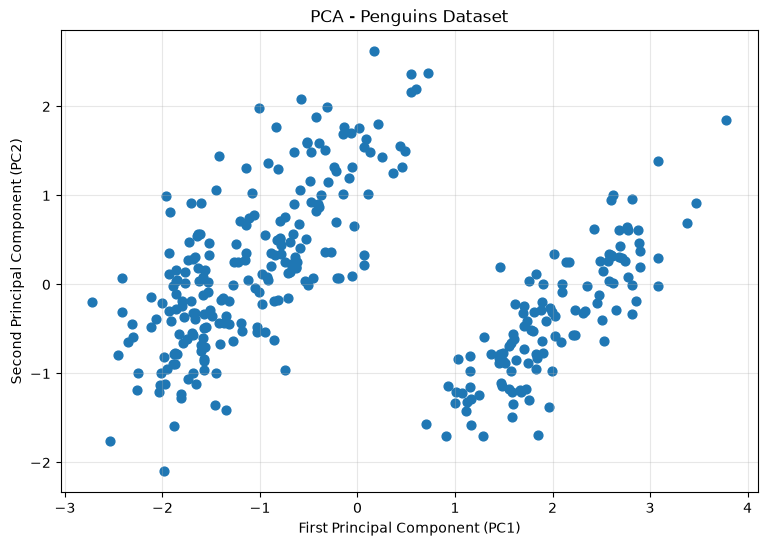

In [33]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_penguins)
plt.figure(figsize=(9, 6))

plt.scatter(X_pca[:, 0], X_pca[:, 1], s=40)

plt.title('PCA - Penguins Dataset')
plt.xlabel('First Principal Component (PC1)')
plt.ylabel('Second Principal Component (PC2)')
plt.grid(alpha=0.3)

plt.show()

#### 17. Display scree plots to determine the optimal number of components and cumulative explained variance

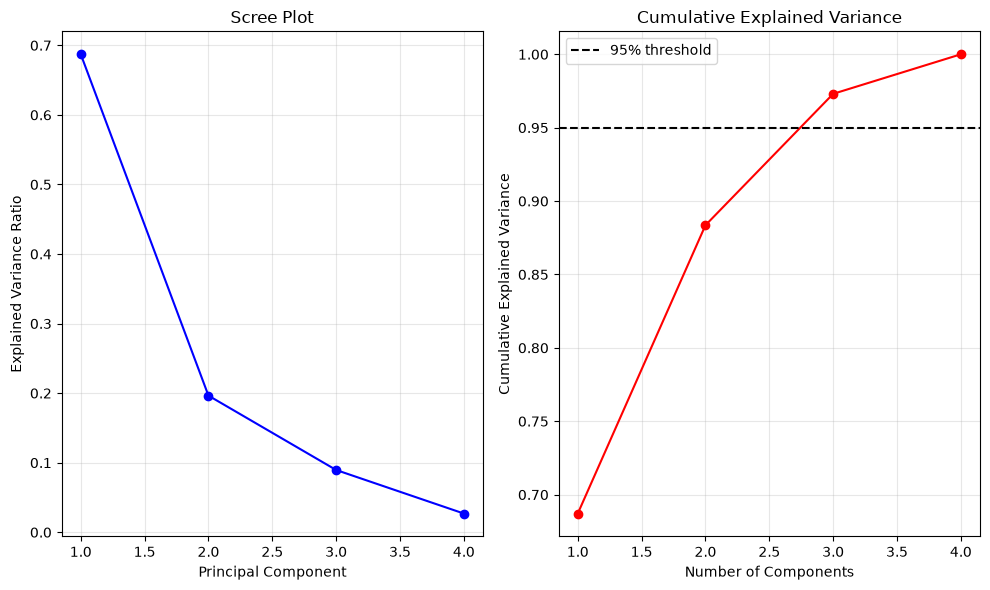

In [34]:
# Apply PCA with all components
pca_full = PCA()
pca_full.fit(X_penguins)

# Plot cumulative explained variance
plt.figure(figsize=(10, 6))
plt.subplot(1, 2, 1)
plt.plot(range(1, len(pca_full.explained_variance_ratio_) + 1), 
         pca_full.explained_variance_ratio_, 'bo-')
plt.xlabel('Principal Component')
plt.ylabel('Explained Variance Ratio')
plt.title('Scree Plot')
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(range(1, len(pca_full.explained_variance_ratio_) + 1),
         np.cumsum(pca_full.explained_variance_ratio_), 'ro-')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('Cumulative Explained Variance')
plt.axhline(y=0.95, color='k', linestyle='--', label='95% threshold')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

#### 18. Calculate (show in numbers) and display component loadings

In [35]:
print("Explained variance by each component:")
for i, var in enumerate(pca_full.explained_variance_ratio_):
    print(f"PC{i+1}: {var:.2%}")

Explained variance by each component:
PC1: 68.71%
PC2: 19.64%
PC3: 8.95%
PC4: 2.69%


In [36]:
# show heatmap
loadings = pd.DataFrame(
    pca_full.components_.T,
    columns=[f'PC{i+1}' for i in range(pca_full.n_components_)],
    index=df_peng.columns
)

loadings

,PC1,PC2,PC3,PC4
culmen_length_mm,0.453174,0.604990,0.637706,-0.148160
culmen_depth_mm,-0.398518,0.792959,-0.431414,0.162115
flipper_length_mm,0.576880,0.003798,-0.231564,0.783309
body_mass_g,0.550478,0.072032,-0.594635,-0.581544


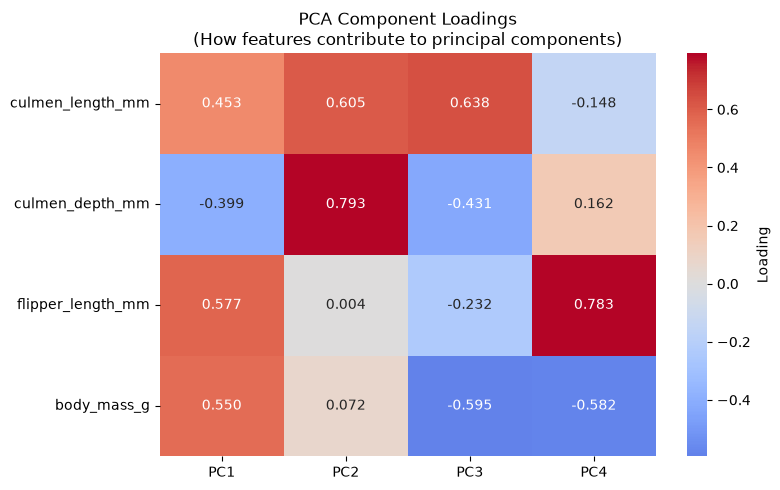

In [37]:
plt.figure(figsize=(8, 5))
sns.heatmap(loadings, annot=True, cmap='coolwarm', center=0, 
            cbar_kws={'label': 'Loading'}, fmt='.3f')
plt.title('PCA Component Loadings\n(How features contribute to principal components)')
plt.tight_layout()
plt.show()

#### 19. Perform logistic regression (or any other classification algorithm) and evaluate the model

In [38]:
# import necessary libraries for model training and evaluation
# Use the PCA-transformed data (X_penguins_pca) and true labels (y_penguins)
# Train and evaluate a model
X_train, X_test, y_train, y_test = train_test_split(
    X_pca,
    y_penguins,
    test_size=0.2,
    random_state=42,
    stratify=y_penguins
)

logreg = LogisticRegression()
logreg.fit(X_train, y_train)
predictions = logreg.predict(X_test)
probabilities = logreg.predict_proba(X_test)[:, 1]
accuracy = accuracy_score(y_test, predictions)
precision = precision_score(y_test, predictions, pos_label='MALE')
recall = recall_score(y_test, predictions, pos_label='MALE')
f1 = f1_score(y_test, predictions, pos_label='MALE')
cnf_matrix = confusion_matrix(y_test, predictions)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1:", f1)
print(cnf_matrix)

Accuracy: 0.8208955223880597
Precision: 0.775
Recall: 0.9117647058823529
F1: 0.8378378378378378
[[24  9]
 [ 3 31]]


c:\Users\gytis.malinauskas\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:1368: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


#### 20. Train the model on all data points, and determine penguin sex for the data, where it was not originally identified

In [39]:
# 1. take entries from original data with sex unknown, scale numerical columns
X_unknown_scaled = scaler.transform(X_unknown)

In [40]:
# 2. apply the same PCA transformation to the new data
X_unknown_pca = pca.transform(X_unknown_scaled)

In [41]:
# 3. Train the model
# Define X_train and y_train using all PCA data from valid data
X_train = X_pca
y_train = y_penguins

# Train a classifier
logreg = LogisticRegression()
logreg.fit(X_train, y_train)

c:\Users\gytis.malinauskas\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:1368: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [42]:
# 4. Make predictions on the new data.
predicted_sex = logreg.predict(X_unknown_pca)

# 5. Display the features and predicted values
unknown_sex['predicted_sex'] = predicted_sex

unknown_sex

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex,predicted_sex
8,34.1,18.1,193.0,3475.0,NaN,FEMALE
10,37.8,17.1,186.0,3300.0,NaN,FEMALE
11,37.8,17.3,180.0,3700.0,NaN,FEMALE
47,37.5,18.9,179.0,2975.0,NaN,FEMALE
246,44.5,14.3,216.0,4100.0,NaN,FEMALE
286,46.2,14.4,214.0,4650.0,NaN,FEMALE
324,47.3,13.8,216.0,4725.0,NaN,FEMALE
336,44.5,15.7,217.0,4875.0,.,FEMALE
